# Grain hunting for DFXM at APS 20-ID-E from a MIDAS grain map

Same workflow as the ID03 / DCT grain-hunting notebook, but for a MIDAS far-field
`Grains.csv` and the 20-ID-E motor stack.

1. load the grain map, tessellate it and colour it by IPF along the tensile axis
2. find reachable reflections (motor names `RX`, `omega`, `samRZ`, `samRX`)
3. pick single grains of interest from their orientation to the tensile axis
4. look at the candidates: IPF triangle, coloured tables, slices, 3D, Paraview

The grain map here is **fake** IF steel (`make_fake_if_steel_grains.py`).
Orientations and positions stay in the MIDAS / ESRF frame (x along the beam,
z up); only the motor angles are in APS terms.

In [1]:
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.spatial import Delaunay, cKDTree

import crispy

## 1. Load, tessellate and colour the grain map

A far-field map only has grain centres, so the grain shapes are a Voronoi
tessellation of the centres (`gmap.tesselate()`). All IPF colours in this
notebook are for `tensile_axis`, given in the MIDAS frame.

In [2]:
file = "Grains_IF_steel.csv"

if not os.path.exists(file):  # regenerate the fake map if it is missing
    subprocess.run([sys.executable, "make_fake_if_steel_grains.py"], check=True)

gmap = crispy.GrainMap(file)

# Tensile (loading) axis in the MIDAS frame: x along beam, y, z up.
# Lab z here = APS y = the omega rotation axis.
tensile_axis = np.array([0.0, 0.0, 1.0])

gmap.tesselate()  # Voronoi cells and volumes
gmap.colorize(ipf_axes=np.array([tensile_axis]))  # g.rgb[:, 0] = IPF colour along tensile axis

ipf_rgb = np.array([g.rgb[:, 0] for g in gmap.grains])

print("Number of grains :", gmap.number_of_grains)
print("Reference cell   :", gmap.reference_cell.lattice_parameters)
print("Space group      :", gmap.reference_cell.symmetry)

Number of grains : 1000
Reference cell   : [ 2.8665  2.8665  2.8665 90.     90.     90.    ]
Space group      : 229


In [3]:
# ---- plotting helpers ------------------------------------------------------

def ipf_slice(gmap, normal, position, colors, n=500, background=(0, 0, 0)):
    """Slice through the Voronoi grain map, as an RGB image.

    normal   : 0, 1 or 2 for a slice perpendicular to x, y or z (MIDAS frame)
    position : where to cut along that axis, in micrometres
    colors   : (number_of_grains, 3) RGB colour per grain
    Returns the two in-plane coordinate grids, the image and the in-plane axis names.
    """
    centroids = gmap.centroids
    inplane = [a for a in range(3) if a != normal]
    lo, hi = centroids.min(axis=0), centroids.max(axis=0)
    a = np.linspace(lo[inplane[0]], hi[inplane[0]], n)
    b = np.linspace(lo[inplane[1]], hi[inplane[1]], n)
    A, B = np.meshgrid(a, b, indexing="ij")
    points = np.zeros((n * n, 3))
    points[:, inplane[0]] = A.ravel()
    points[:, inplane[1]] = B.ravel()
    points[:, normal] = position
    _, nearest = cKDTree(centroids).query(points)
    image = np.asarray(colors)[nearest]
    outside = Delaunay(centroids).find_simplex(points) < 0  # outside the sample
    image[outside] = background
    names = [("x", "y", "z")[i] for i in inplane]
    return A, B, image.reshape(n, n, 3), names


def plot_slice(ax, gmap, normal, position, colors, title=""):
    A, B, image, names = ipf_slice(gmap, normal, position, colors)
    ax.pcolormesh(A, B, image, rasterized=True)
    ax.set_xlabel(f"{names[0]} [um]")
    ax.set_ylabel(f"{names[1]} [um]")
    ax.set_title(title)
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_visible(False)


def ipf_xy(gmap, axis):
    """Position of every grain in the cubic IPF triangle (001-101-111) for a sample axis."""
    d = np.abs(np.array([g.u.T @ axis for g in gmap.grains]))
    d = np.sort(d / np.linalg.norm(d, axis=1)[:, None], axis=1)
    return d[:, 1] / (1 + d[:, 2]), d[:, 0] / (1 + d[:, 2])


def draw_ipf_triangle(ax):
    t = np.linspace(0, 1, 50)
    arc = np.sort(np.stack((np.ones_like(t), t, np.ones_like(t)), axis=1), axis=1)
    arc /= np.linalg.norm(arc, axis=1)[:, None]
    x = np.concatenate(([0], arc[:, 1] / (1 + arc[:, 2]), [0]))
    y = np.concatenate(([0], arc[:, 0] / (1 + arc[:, 2]), [0]))
    ax.plot(x, y, color="k", lw=1)
    ax.text(0, -0.012, "001", ha="center", va="top")
    ax.text(x[1], -0.012, "101", ha="center", va="top")
    ax.text(x[-2], y[-2] + 0.008, "111", ha="center", va="bottom")
    ax.set_aspect("equal")
    ax.axis("off")


def grain_color_style(gmap, column="grain id"):
    """Row style for pandas: paint the grain id cell with the grain's IPF colour."""
    def style(row):
        rgb = (gmap.grains[int(row[column])].rgb[:, 0] * 255).astype(int)
        return pd.Series("background-color: #%02x%02x%02x; color: black" % tuple(rgb), row.index)
    return style

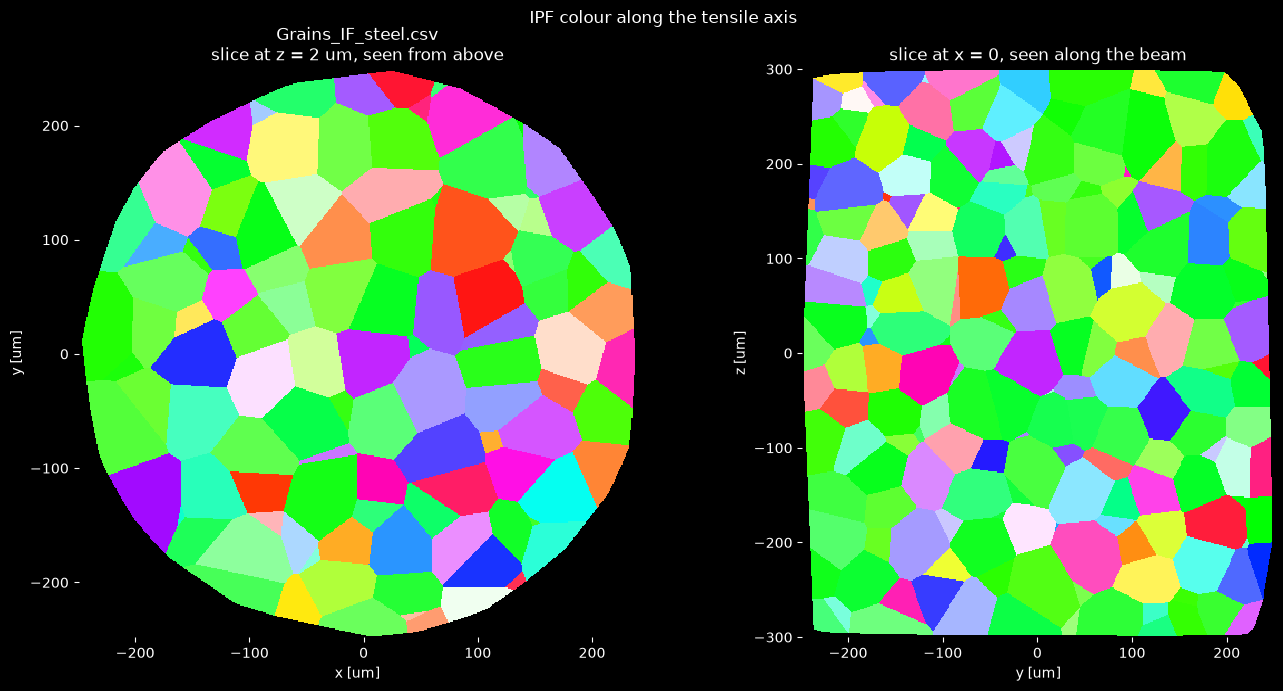

In [4]:
z_mid = gmap.centroids[:, 2].mean()

with plt.style.context("dark_background"):
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    plot_slice(ax[0], gmap, 2, z_mid, ipf_rgb, f"{file}\nslice at z = {z_mid:.0f} um, seen from above")
    plot_slice(ax[1], gmap, 0, 0.0, ipf_rgb, "slice at x = 0, seen along the beam")
    fig.suptitle("IPF colour along the tensile axis")
    plt.tight_layout()
    plt.show()

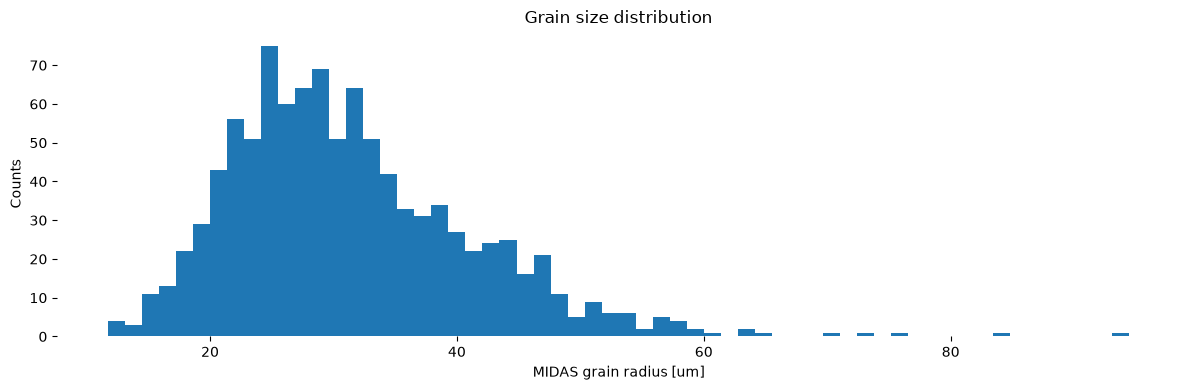

390 of 1000 grains touch the sample surface (Voronoi)


In [5]:
radius = np.array([g.midas["GrainRadius"] for g in gmap.grains])

fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.hist(radius, bins=60)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel("MIDAS grain radius [um]")
ax.set_ylabel("Counts")
ax.set_title("Grain size distribution")
plt.tight_layout()
plt.show()

on_boundary = np.array([g.is_on_boundary for g in gmap.grains])
print(f"{on_boundary.sum()} of {gmap.number_of_grains} grains touch the sample surface (Voronoi)")

## 2. Microscope settings

Real 20-ID-E motor names. Rotations are right-handed about the APS laboratory
axes (z along the beam, y up); stack from the base: hexapod `RX` → `omega`
(about y) → `samRZ` → `samRX`. `detector_y` is vertical and `detector_x`
horizontal, in metres from the direct beam.

In [6]:
energy = 20.0  # keV                       <-- placeholder
detector_distance = 4.0  # metres          <-- placeholder
eta = 0.0  # degrees, 0 = scattering straight up

motor_bounds = {
    "RX": (-20, 20),  # degrees            <-- placeholder
    "omega": (-180, 180),  # degrees       <-- placeholder
    "samRZ": (-8, 8),  # degrees           <-- placeholder
    "samRX": (-8, 8),  # degrees           <-- placeholder
    "detector_y": (-0.04, 1.96),  # metres <-- placeholder
    "detector_x": (-0.169, 1.16),  # metres <-- placeholder
}

In [7]:
goni = crispy.dfxm.Goniometer(
    gmap,
    energy=energy,
    detector_distance=detector_distance,
    motor_bounds=motor_bounds,
    eta=eta,
    beamline="APS",
)

print("Number of grains: ", gmap.number_of_grains)

Number of grains:  1000


In [8]:
# Which hkl families are inside the detector travel?
two_theta_max = np.degrees(np.arctan(motor_bounds["detector_y"][1] / detector_distance))
print(f"Maximum reachable 2theta = {two_theta_max:.3f} deg  (theta = {two_theta_max / 2:.3f} deg)\n")

hkls = goni._get_hkls()
d_spacing = 1 / np.linalg.norm(gmap.reference_cell.B @ hkls, axis=0)
theta = np.degrees(np.arcsin(goni.wavelength / (2 * d_spacing)))
families = {}
for hkl, d, th in zip(hkls.T, d_spacing, theta):
    key = tuple(sorted(np.abs(hkl).astype(int), reverse=True))
    families.setdefault(key, [0, d, th])[0] += 1

print("   hkl    multiplicity   d [A]   theta [deg]   2theta [deg]   detector_y [m]")
for key, (count, d, th) in sorted(families.items(), key=lambda kv: -kv[1][1]):
    y = detector_distance * np.tan(np.radians(2 * th))
    print(f"  {{{''.join(map(str, key))}}}  {count:8d}      {d:6.3f}  {th:9.3f}    {2 * th:9.3f}     {y:9.3f}")
print(f"\n{hkls.shape[1]} reflections are tried per grain")

Maximum reachable 2theta = 26.105 deg  (theta = 13.052 deg)

   hkl    multiplicity   d [A]   theta [deg]   2theta [deg]   detector_y [m]
  {110}        12       2.027      8.796       17.593         1.268
  {200}         6       1.433     12.490       24.979         1.863

18 reflections are tried per grain


## 3. Find reflections

The solution is not unique: re-running can give different, equally valid,
motor angles for the same reflection.

In [9]:
goni.find_reflections(mask_unreachable=True)

df = goni.table_of_reflections()
df["grain id"] = df["grain id"].astype(int)
df[["h", "k", "l"]] = df[["h", "k", "l"]].astype(int)
df["midas id"] = [gmap.grains[i].midas_id for i in df["grain id"]]

has_reflection = np.array([g.dfxm is not None for g in gmap.grains])
print(f" Total number of found reflections : {df.shape[0]} ")
print(f" Out of {gmap.number_of_grains} grains, {has_reflection.sum()} have accessible reflections.")

 Total number of found reflections : 1278 
 Out of 1000 grains, 904 have accessible reflections.


In [10]:
# Full table (grain id cell painted with the IPF colour along the tensile axis).
# Only the first rows are shown; use df for everything.
n_rows_shown = 30
display(df.head(n_rows_shown).style.apply(grain_color_style(gmap), axis=1, subset=["grain id"]).format(precision=3))
df.to_csv("reflections_APS.csv", index=False)

,grain id,h,k,l,RX [dgr],omega [dgr],samRZ [dgr],samRX [dgr],2 theta [dgr],eta [dgr],detector_y [mm],detector_x [mm],midas id
0,0,-1,0,1,0.527,32.706,7.941,-7.926,17.598,0.000,1268.715,-0.000,1
1,0,-2,0,0,20.000,-17.708,-4.739,5.141,24.991,0.000,1864.484,-0.000,1
2,1,0,1,1,7.830,79.134,4.399,2.775,17.602,0.000,1269.038,-0.000,2
3,1,0,2,0,2.477,-82.235,-7.923,-8.000,24.984,0.000,1863.911,-0.000,2
4,2,1,1,0,-19.933,30.093,-5.734,2.012,17.598,0.000,1268.689,-0.000,3
5,3,-1,0,-1,6.978,-32.825,-4.085,-7.970,17.593,0.000,1268.358,-0.000,4
6,4,1,0,1,-5.677,3.309,-0.117,-2.341,17.603,0.000,1269.089,-0.000,5
7,5,0,1,1,-3.159,-28.648,-7.985,-7.992,17.591,0.000,1268.166,-0.000,6
8,6,0,1,1,17.311,-39.299,-7.987,6.241,17.597,0.000,1268.669,-0.000,7
9,7,0,-1,1,-12.478,18.607,2.149,2.133,17.590,0.000,1268.135,-0.000,8


## 4. Grains of interest: orientation to the tensile axis

A grain is "of interest" when one of the `preferred_family` plane normals lies
within `alignment_threshold` degrees of the tensile axis **and** it has a
reachable reflection. `wedge` is that angle. For {110} these are the green
grains in the IPF colouring, {111} blue, {100} red.

In [11]:
preferred_family = (1, 1, 0)  # crystal direction wanted along the tensile axis
alignment_threshold = 15  # degrees

# all symmetry equivalent directions of the family (cubic)
from itertools import permutations, product
preferred_hkl = np.array(sorted({
    tuple(s * np.array(p))
    for p in permutations(preferred_family)
    for s in product([1, -1], repeat=3)
})).T

def wedge_to_axis(grain):
    """Smallest angle [deg] between the tensile axis and the preferred family."""
    Q = grain.ub @ preferred_hkl
    qhat = Q / np.linalg.norm(Q, axis=0)
    return np.degrees(np.arccos(np.clip(qhat.T @ tensile_axis, -1, 1))).min()

wedge = np.array([wedge_to_axis(g) for g in gmap.grains])
aligned = wedge < alignment_threshold
of_interest = aligned & has_reflection

print(f"{aligned.sum()} grains have {preferred_family} within {alignment_threshold} deg of the tensile axis")
print(f"{of_interest.sum()} of these also have an accessible reflection")

500 grains have (1, 1, 0) within 15 deg of the tensile axis
460 of these also have an accessible reflection


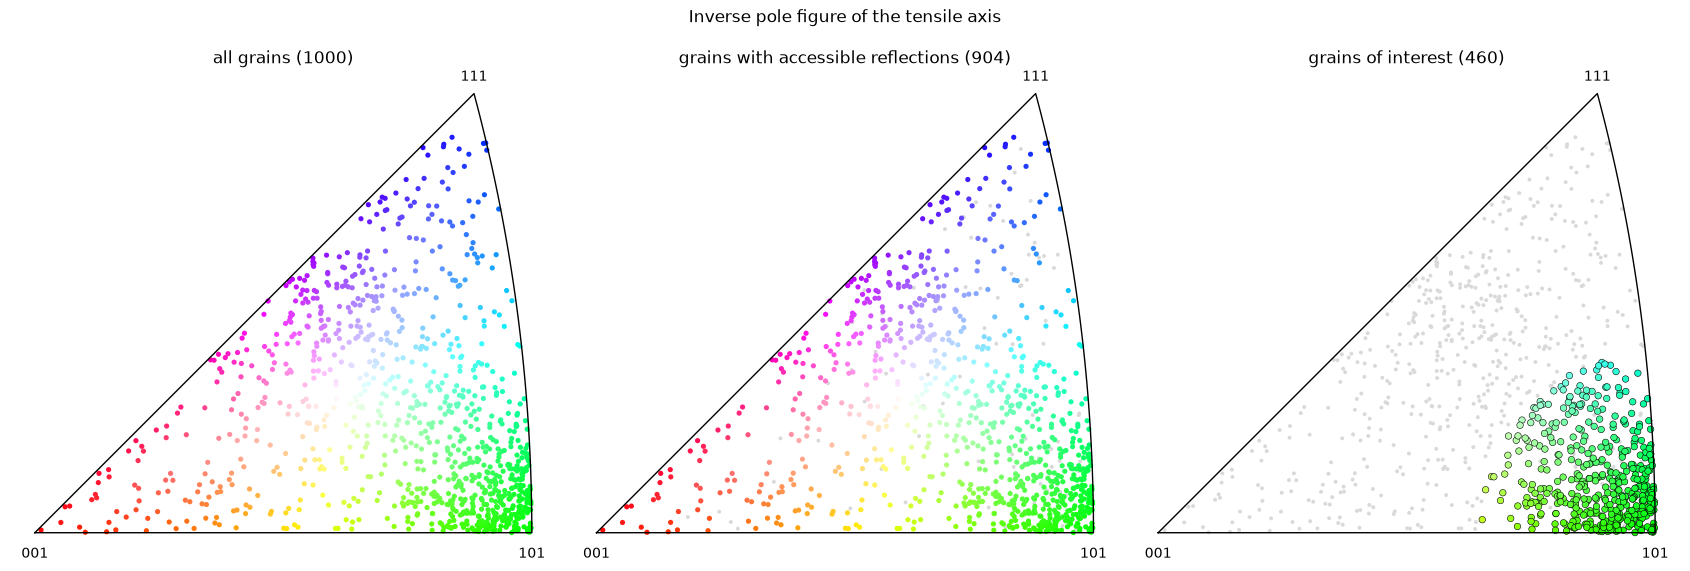

In [12]:
# Where the grains sit in the IPF triangle of the tensile axis.
x_ipf, y_ipf = ipf_xy(gmap, tensile_axis)

fig, ax = plt.subplots(1, 3, figsize=(17, 6))
for a in ax:
    draw_ipf_triangle(a)

ax[0].scatter(x_ipf, y_ipf, s=14, c=ipf_rgb, edgecolors="none")
ax[0].set_title(f"all grains ({gmap.number_of_grains})")

ax[1].scatter(x_ipf[~has_reflection], y_ipf[~has_reflection], s=8, c="0.85", edgecolors="none")
ax[1].scatter(x_ipf[has_reflection], y_ipf[has_reflection], s=14, c=ipf_rgb[has_reflection], edgecolors="none")
ax[1].set_title(f"grains with accessible reflections ({has_reflection.sum()})")

ax[2].scatter(x_ipf[~of_interest], y_ipf[~of_interest], s=8, c="0.85", edgecolors="none")
ax[2].scatter(x_ipf[of_interest], y_ipf[of_interest], s=22, c=ipf_rgb[of_interest], edgecolors="k", linewidths=0.4)
ax[2].set_title(f"grains of interest ({of_interest.sum()})")

fig.suptitle("Inverse pole figure of the tensile axis")
plt.tight_layout()
plt.show()

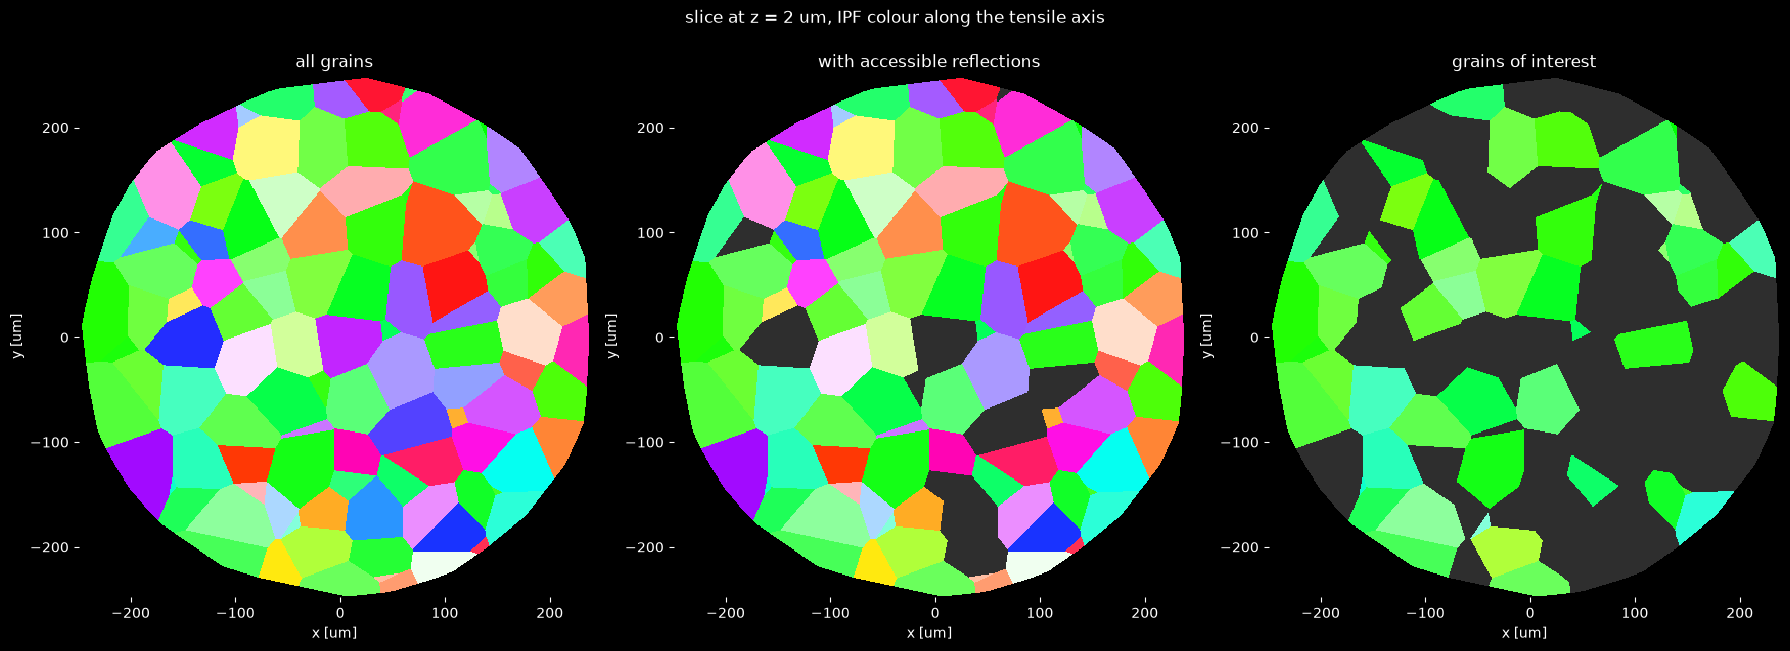

In [13]:
# Same three groups in the grain map: everything that is not selected is greyed out.
grey = np.full_like(ipf_rgb, 0.18)
rgb_reflection = np.where(has_reflection[:, None], ipf_rgb, grey)
rgb_interest = np.where(of_interest[:, None], ipf_rgb, grey)

with plt.style.context("dark_background"):
    fig, ax = plt.subplots(1, 3, figsize=(18, 6.5))
    plot_slice(ax[0], gmap, 2, z_mid, ipf_rgb, "all grains")
    plot_slice(ax[1], gmap, 2, z_mid, rgb_reflection, "with accessible reflections")
    plot_slice(ax[2], gmap, 2, z_mid, rgb_interest, "grains of interest")
    fig.suptitle(f"slice at z = {z_mid:.0f} um, IPF colour along the tensile axis")
    plt.tight_layout()
    plt.show()

## 5. Table of grains of interest

Best aligned grain first. The `grain id` cell has the grain's IPF colour;
`h k l` is the crystal direction along the tensile axis and `wedge` the angle
between the tensile axis and the nearest `preferred_family` direction.

In [14]:
def crystal_direction(grain):
    d = grain.u.T @ tensile_axis
    return d / np.linalg.norm(d)

ranked = np.flatnonzero(of_interest)
ranked = ranked[np.argsort(wedge[ranked])]  # best aligned first

directions = np.array([crystal_direction(gmap.grains[i]) for i in ranked]).reshape(-1, 3)
positions = gmap.centroids[ranked]
df_interest = pd.DataFrame({
    "grain id": ranked,
    "midas id": [gmap.grains[i].midas_id for i in ranked],
    "h": directions[:, 0],
    "k": directions[:, 1],
    "l": directions[:, 2],
    "wedge [dgr]": wedge[ranked],
    "reflections": [len(gmap.grains[i].dfxm["theta"]) for i in ranked],
    "radius [um]": radius[ranked],
    "x [um]": positions[:, 0],
    "y [um]": positions[:, 1],
    "z [um]": positions[:, 2],
    "on surface": on_boundary[ranked],
})

print(f" ---- Total number of candidate grains for DFXM is {len(ranked)} ----- ")

n_grains_shown = 25
display(df_interest.head(n_grains_shown).style.apply(grain_color_style(gmap), axis=1, subset=["grain id"]).format(precision=2))
df_interest.to_csv("grains_of_interest_APS.csv", index=False)

 ---- Total number of candidate grains for DFXM is 460 ----- 


,grain id,midas id,h,k,l,wedge [dgr],reflections,radius [um],x [um],y [um],z [um],on surface
0,382,383,-0.70,-0.71,0.00,0.19,1,33.07,-115.49,4.20,83.34,False
1,866,867,-0.00,-0.71,-0.70,0.29,1,29.41,-105.42,219.67,51.07,True
2,545,546,0.71,-0.70,0.00,0.31,1,26.16,-92.05,187.55,-150.72,True
3,892,893,-0.71,0.70,-0.00,0.34,1,33.38,-55.85,145.11,163.18,False
4,894,895,-0.00,-0.70,-0.71,0.36,1,36.09,-112.69,-217.49,40.17,True
5,338,339,-0.71,-0.71,0.01,0.40,1,25.08,-16.99,246.45,-179.16,True
6,354,355,0.71,0.70,0.01,0.45,1,28.71,-36.96,198.01,298.92,True
7,97,98,-0.71,0.70,-0.00,0.47,1,56.79,-175.50,-168.70,-159.22,True
8,240,241,0.01,-0.71,-0.71,0.50,1,37.74,129.08,182.46,-29.84,False
9,4,5,0.71,0.01,0.71,0.78,1,32.66,33.66,208.48,-161.94,True


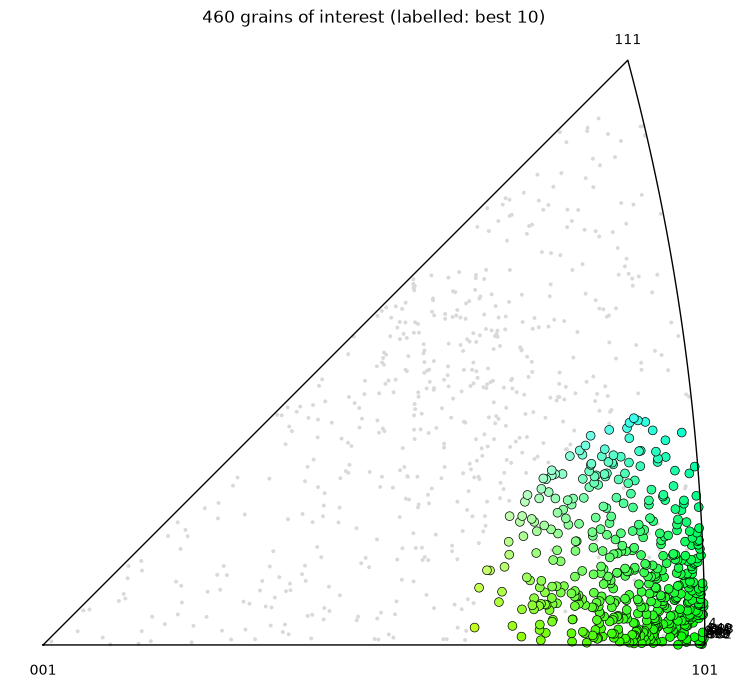

In [15]:
# The grains of interest in the IPF triangle, the best ones labelled with their grain id.
n_labelled = 10

fig, ax = plt.subplots(1, 1, figsize=(8, 7))
draw_ipf_triangle(ax)
ax.scatter(x_ipf, y_ipf, s=8, c="0.85", edgecolors="none")
ax.scatter(x_ipf[ranked], y_ipf[ranked], s=40, c=ipf_rgb[ranked], edgecolors="k", linewidths=0.5)
for i in ranked[:n_labelled]:
    ax.annotate(str(i), (x_ipf[i], y_ipf[i]), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.set_title(f"{len(ranked)} grains of interest (labelled: best {n_labelled})")
plt.tight_layout()
plt.show()

## 6. Look at one grain

Set `grain_index` to a `grain id` from the table above.

In [16]:
grain_index = int(ranked[0]) if len(ranked) else None  # <-- pick a grain id from the table above

if grain_index is None:
    print("No grains of interest with these settings. Relax alignment_threshold or the motor bounds.")
else:
    grain = gmap.grains[grain_index]
    print("grain id / midas id   :", grain_index, "/", grain.midas_id)
    print("position [um]         :", np.round(grain.translation, 1), "(MIDAS frame)")
    print("radius [um]           :", round(radius[grain_index], 1))
    print("crystal dir. || axis  :", np.round(crystal_direction(grain), 2))
    print("wedge [dgr]           :", round(wedge[grain_index], 2))
    print("on sample surface     :", bool(on_boundary[grain_index]))

grain id / midas id   : 382 / 383
position [um]         : [-115.5    4.2   83.3] (MIDAS frame)
radius [um]           : 33.1
crystal dir. || axis  : [-0.7  -0.71  0.  ]
wedge [dgr]           : 0.19
on sample surface     : False


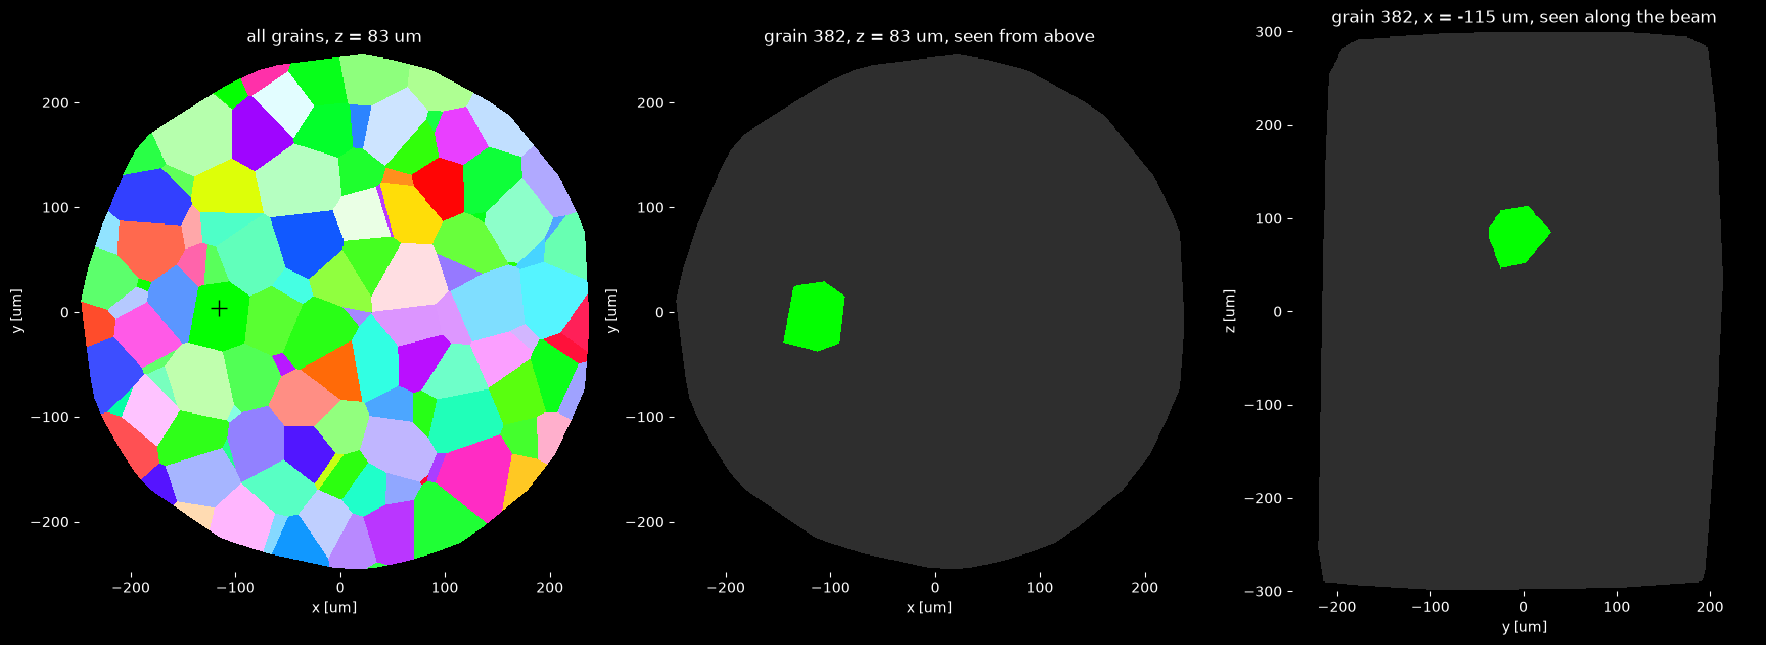

In [17]:
# Where the grain sits: slices through its centre, all other grains greyed out.
if grain_index is not None:
    is_grain = np.arange(gmap.number_of_grains) == grain_index
    rgb_grain = np.where(is_grain[:, None], ipf_rgb, grey)
    cx, cy, cz = grain.translation

    with plt.style.context("dark_background"):
        fig, ax = plt.subplots(1, 3, figsize=(18, 6.5))
        plot_slice(ax[0], gmap, 2, cz, ipf_rgb, f"all grains, z = {cz:.0f} um")
        plot_slice(ax[1], gmap, 2, cz, rgb_grain, f"grain {grain_index}, z = {cz:.0f} um, seen from above")
        plot_slice(ax[2], gmap, 0, cx, rgb_grain, f"grain {grain_index}, x = {cx:.0f} um, seen along the beam")
        ax[0].plot(cx, cy, "k+", ms=12)
        plt.tight_layout()
        plt.show()

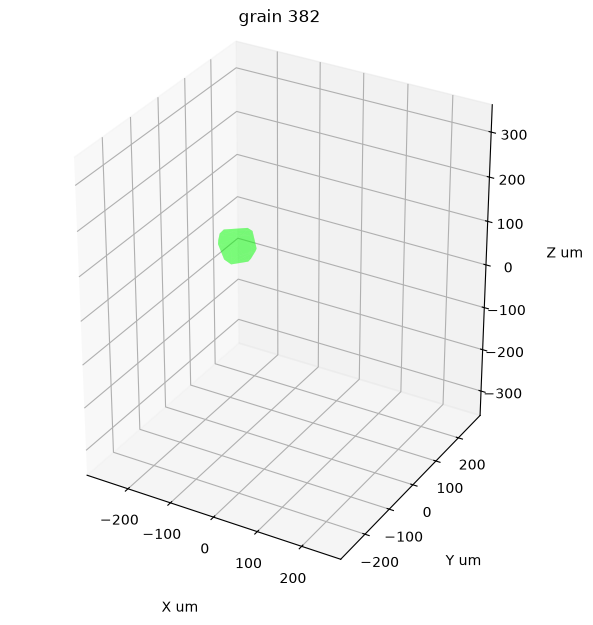

In [18]:
# 3D view of the grain's Voronoi cell inside the sample, IPF colour along the tensile axis.
if grain_index is not None:
    fig, ax = crispy.vizualise.mesh(gmap, select=[grain_index])
    ax.set_title(f"grain {grain_index}")
    plt.show()

In [19]:
# Motor positions for every reflection of the grain.
if grain_index is not None:
    df_grain = df[df["grain id"] == grain_index]
    display(df_grain.style.apply(grain_color_style(gmap), axis=1, subset=["grain id"]).format(precision=3))

,grain id,h,k,l,RX [dgr],omega [dgr],samRZ [dgr],samRX [dgr],2 theta [dgr],eta [dgr],detector_y [mm],detector_x [mm],midas id
497,382,-1,-1,0,-11.955,0.739,0.124,3.333,17.596,0.000,1268.585,-0.000,383


In [20]:
# Write the grain for Paraview (ipf-x, ipf-y, ipf-z colours are included).
if grain_index is not None:
    out = file.replace(".csv", "") + f"_grain_{grain_index}"
    gmap.write(out, grains=[grain_index])
    print("wrote", out + ".vtk")

wrote Grains_IF_steel_grain_382.vtk
